# Voyager 1 & 2 Trajectory Data — Exploration (Step 1)

**Goal of this notebook:** characterize the SSCWeb ephemeris data for Voyager 1 and Voyager 2 *before* we commit to the anomaly-detection design.
By the end we should be able to write a short summary covering: available variables, time coverage, actual sampling cadence, coordinate systems, data format, and any gaps or oddities.

Pipeline (planned): **ephemeris → trajectory analysis → feature extraction → anomaly detection → investigation of detected periods**

In [ ]:
!pip install -q sscws pandas numpy matplotlib astropy astroquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.4/83.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 55.0 MB/s eta 0:00:00


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sscws.sscws import SscWs
from sscws.coordinates import CoordinateSystem

ssc = SscWs()
AU_KM = 149_597_870.7

## 1. Observatory metadata

This replaces the raw XML string search: `sscws` parses the observatory list for us.
Note the listed `Resolution` is SSCWeb's nominal value; we measure the **actual** cadence in Section 3.

In [ ]:
obs = ssc.get_observatories()
meta = pd.DataFrame(obs['Observatory'])
voy = meta[meta['Id'].isin(['voyager1', 'voyager2'])]
voy[['Id', 'Name', 'Resolution', 'StartTime', 'EndTime']]

,Id,Name,Resolution,StartTime,EndTime
315,voyager1,Voyager1,60,1977-09-06 00:00:29+00:00,2030-12-31 22:59:30+00:00
316,voyager2,Voyager2,60,1977-08-21 00:00:29+00:00,2030-12-31 22:59:30+00:00


**Important:** the end date (2030-12-31) is in the future. Everything after "today" is a *predicted* trajectory, and even the
recent past may be predicted rather than reconstructed. We keep only data up to the present and flag this in the summary.

## 2. Test request: one year, all coordinate systems

Start small to learn what the response looks like before pulling ~50 years.

In [ ]:
ALL_CS = [CoordinateSystem.GEO, CoordinateSystem.GM, CoordinateSystem.GSE,
          CoordinateSystem.GSM, CoordinateSystem.SM,
          CoordinateSystem.GEI_TOD, CoordinateSystem.GEI_J_2000]

def try_request(label, sc, t_range, cs_list):
    res = ssc.get_locations([sc], t_range, cs_list)
    status = res.get('HttpStatus')
    print(f'{label:<35} status {status}')
    if status != 200:
        print('   ErrorMessage    :', res.get('ErrorMessage'))
        print('   ErrorDescription:', res.get('ErrorDescription'))
        print('   HttpText        :', str(res.get('HttpText'))[:300])
    return res

t79 = ['1979-01-01T00:00:00Z', '1979-01-02T00:00:00Z']   # 1 day only
t25 = ['2025-01-01T00:00:00Z', '2025-01-02T00:00:00Z']

r1 = try_request('A: GSE only, 1979',        'voyager1', t79, [CoordinateSystem.GSE])
r2 = try_request('B: GSE only, 2025',        'voyager1', t25, [CoordinateSystem.GSE])
r3 = try_request('C: GEI_J_2000 only, 1979', 'voyager1', t79, [CoordinateSystem.GEI_J_2000])
r4 = try_request('D: all 7 systems, 1979',   'voyager1', t79, ALL_CS)
for cs in ALL_CS:
    try_request(f'E: {cs.name} alone, 1979', 'voyager1', t79, [cs])

# If any request succeeded, show what the data looks like
for r in (r1, r2, r3, r4):
    if r.get('HttpStatus') == 200 and r.get('Data'):
        d = r['Data'][0]
        print('\nTop-level keys :', list(d.keys()))
        for c in d['Coordinates']:
            print(c['CoordinateSystem'], '->', [k for k in c.keys() if k != 'CoordinateSystem'])
        print('First times    :', d['Time'][:5])
        break

A: GSE only, 1979                   status 200
B: GSE only, 2025                   status 200
C: GEI_J_2000 only, 1979            status 400
   ErrorMessage    : Invalid Request.
   ErrorDescription: Output of local time value is not valid for GEI_J2000 coordinates as specified in the 5th coordinate listing option
   HttpText        : None
D: all 7 systems, 1979              status 400
   ErrorMessage    : Invalid Request.
   ErrorDescription: Output of local time value is not valid for GSM coordinates as specified in the 23th coordinate listing option
   HttpText        : None
E: GEO alone, 1979                  status 200
E: GM alone, 1979                   status 200
E: GSE alone, 1979                  status 200
E: GSM alone, 1979                  status 400
   ErrorMessage    : Invalid Request.
   ErrorDescription: Output of local time value is not valid for GSM coordinates as specified in the 5th coordinate listing option
   HttpText        : None
E: SM alone, 1979               

In [ ]:
def show(label, t_range):
    res = ssc.get_locations(['voyager1'], t_range, [CoordinateSystem.GSE])
    print(f'{label:<12} status {res.get("HttpStatus")}')
    if res.get('HttpStatus') != 200:
        print('   ErrorMessage    :', res.get('ErrorMessage'))
        print('   ErrorDescription:', res.get('ErrorDescription'))
        print('   HttpText        :', str(res.get('HttpText'))[:500])
    else:
        print('   points returned :', len(res['Data'][0]['Time']))

show('1 day',   ['1979-01-01T00:00:00Z', '1979-01-02T00:00:00Z'])
show('1 month', ['1979-01-01T00:00:00Z', '1979-02-01T00:00:00Z'])
show('1 year',  ['1979-01-01T00:00:00Z', '1980-01-01T00:00:00Z'])

1 day        status 200
   points returned : 1440
1 month      status 200
   points returned : 44640
1 year       status 200
   points returned : 525601


## 3. Pull the full mission, year by year

We request one year at a time (smaller, more reliable requests) in **GSE** and **GEI_J_2000**.
GEI_J_2000 is the one we need later to convert to a Sun-centered frame (Section 5).
Raw pulls are saved to CSV so we don't hit the server again.

In [ ]:
from sscws.request import DataRequest, SatelliteSpecification
from sscws.outputoptions import OutputOptions, CoordinateOptions
from sscws.coordinates import CoordinateComponent
from sscws.timeinterval import TimeInterval

RES_FACTOR = 60   # SSCWeb base cadence is 60 s -> factor 60 = hourly points

def fetch_year(sc_id, year, cs_list=(CoordinateSystem.GSE, CoordinateSystem.GEI_J_2000),
               res_factor=RES_FACTOR):
    t0, t1 = f'{year}-01-01T00:00:00Z', f'{year+1}-01-01T00:00:00Z'
    opts = [CoordinateOptions(cs, comp) for cs in cs_list
            for comp in (CoordinateComponent.X, CoordinateComponent.Y, CoordinateComponent.Z)]
    req = DataRequest(f'{sc_id} {year}', TimeInterval(t0, t1),
                      [SatelliteSpecification(sc_id, res_factor)], None, OutputOptions(opts))
    res = ssc.get_locations(req)
    if res.get('HttpStatus') != 200 or not res.get('Data'):
        print(f'  {sc_id} {year}: no data (status {res.get("HttpStatus")})')
        print('    ', res.get('ErrorMessage'), '|', res.get('ErrorDescription'))
        return None
    d = res['Data'][0]
    df = pd.DataFrame({'time': pd.to_datetime(d['Time'], utc=True)})
    for c in d['Coordinates']:
        cs = c['CoordinateSystem'].name.lower()   # e.g. 'gse', 'gei_j_2000'
        for axis in ('X', 'Y', 'Z'):
            if c.get(axis) is not None:
                df[f'{axis.lower()}_{cs}_km'] = np.asarray(c[axis], dtype=float)
    return df

def fetch_mission(sc_id, first_year, last_year):
    parts = []
    for yr in range(first_year, last_year + 1):
        df = fetch_year(sc_id, yr)
        if df is not None:
            parts.append(df)
            print(f'  {sc_id} {yr}: {len(df):,} rows')
        time.sleep(1)   # be polite to the server
    out = pd.concat(parts).drop_duplicates('time').sort_values('time').reset_index(drop=True)
    return out

In [ ]:
test = fetch_year('voyager1', 1979)
print(test.shape)
test.head()

(8761, 7)


,time,x_gei_j_2000_km,y_gei_j_2000_km,z_gei_j_2000_km,x_gse_km,y_gse_km,z_gse_km
0,1979-01-01 00:00:30+00:00,-3.856761e+08,4.173147e+08,1.898883e+08,-5.197755e+08,-2.978614e+08,8.200631e+06
1,1979-01-01 01:00:30+00:00,-3.856154e+08,4.173474e+08,1.899025e+08,-5.200204e+08,-2.974099e+08,8.200652e+06
2,1979-01-01 02:00:30+00:00,-3.855548e+08,4.173802e+08,1.899168e+08,-5.202650e+08,-2.969583e+08,8.200661e+06
3,1979-01-01 03:00:30+00:00,-3.854941e+08,4.174131e+08,1.899310e+08,-5.205092e+08,-2.965065e+08,8.200674e+06
4,1979-01-01 04:00:30+00:00,-3.854335e+08,4.174460e+08,1.899453e+08,-5.207532e+08,-2.960545e+08,8.200690e+06


In [ ]:
TODAY_YEAR = pd.Timestamp.now(tz='UTC').year
raw = {}
for sc in ['voyager1', 'voyager2']:
    raw[sc] = fetch_mission(sc, 1977, TODAY_YEAR)
    raw[sc] = raw[sc][raw[sc]['time'] <= pd.Timestamp.now(tz='UTC')]   # drop predicted future
    raw[sc].to_csv(f'{sc}_sscweb_raw.csv', index=False)
    print(sc, raw[sc].shape)

  voyager1 1977: 2,809 rows
  voyager1 1978: 8,761 rows
  voyager1 1979: 8,761 rows
  voyager1 1980: 8,785 rows
  voyager1 1981: 8,761 rows
  voyager1 1982: 8,761 rows
  voyager1 1983: 8,761 rows
  voyager1 1984: 8,785 rows
  voyager1 1985: 8,761 rows
  voyager1 1986: 8,761 rows
  voyager1 1987: 8,761 rows
  voyager1 1988: 8,785 rows
  voyager1 1989: 8,761 rows
  voyager1 1990: 8,761 rows
  voyager1 1991: 8,761 rows
  voyager1 1992: 8,785 rows
  voyager1 1993: 8,761 rows
  voyager1 1994: 8,761 rows
  voyager1 1995: 8,761 rows
  voyager1 1996: 8,785 rows
  voyager1 1997: 8,761 rows
  voyager1 1998: 8,761 rows
  voyager1 1999: 8,761 rows
  voyager1 2000: 8,785 rows
  voyager1 2001: 8,761 rows
  voyager1 2002: 8,761 rows
  voyager1 2003: 8,761 rows
  voyager1 2004: 8,785 rows
  voyager1 2005: 8,761 rows
  voyager1 2006: 8,761 rows
  voyager1 2007: 8,761 rows
  voyager1 2008: 8,785 rows
  voyager1 2009: 8,761 rows
  voyager1 2010: 8,761 rows
  voyager1 2011: 8,761 rows
  voyager1 2012: 8,7

## 4. Data-quality summary (this is the table for our brief report)

In [ ]:
def quality_summary(df, name):
    dt = df['time'].diff().dt.total_seconds().dropna()
    num = df.select_dtypes('number')
    return pd.Series({
        'spacecraft': name,
        'first time': df['time'].min(),
        'last time': df['time'].max(),
        'rows': len(df),
        'variables': ', '.join(num.columns),
        'median step (s)': dt.median(),
        'min step (s)': dt.min(),
        'max step (s)': dt.max(),
        'distinct step sizes': dt.round().nunique(),
        'gaps > 2x median': int((dt > 2 * dt.median()).sum()),
        'missing values': int(num.isna().sum().sum()),
        'duplicate times': int(df['time'].duplicated().sum()),
    })

summary = pd.DataFrame([quality_summary(raw[s], s) for s in raw]).T
summary

In [ ]:
# Where are the gaps, and does the cadence change over the mission?
for sc, df in raw.items():
    dt = df['time'].diff().dt.total_seconds()
    print(f'\n{sc}: step-size counts (seconds)')
    print(dt.round().value_counts().head(10))
    big = df.loc[dt > 2 * dt.median(), 'time']
    print(f'{sc}: first 20 gap end-times')
    print(big.head(20).to_string())


voyager1: step-size counts (seconds)
time
3600.0    430050
Name: count, dtype: int64
voyager1: first 20 gap end-times
Series([], )

voyager2: step-size counts (seconds)
time
3600.0    430434
Name: count, dtype: int64
voyager2: first 20 gap end-times
Series([], )


## 5. Convert to a Sun-centered frame

All SSCWeb systems are **Earth-centered**. At 50–170 AU the Voyagers barely move relative to the Sun on short timescales,
but Earth swings ±1 AU around the Sun every year, so geocentric positions (and any velocity derived from them) carry a strong
**1-year oscillation that is Earth's motion, not Voyager's**. An anomaly detector fed geocentric data would mostly learn Earth's orbit.

Fix: heliocentric position = Earth's heliocentric position + Voyager's geocentric position, both in the J2000 equatorial frame.

In [ ]:
from astropy.time import Time
from astropy.coordinates import get_body_barycentric

def to_heliocentric(df):
    t = Time(df['time'].dt.tz_convert(None).values)
    earth = get_body_barycentric('earth', t).xyz.to('km').value
    sun   = get_body_barycentric('sun',   t).xyz.to('km').value
    e_helio = earth - sun                                   # shape (3, N)
    out = df[['time']].copy()
    out['x_au'] = (e_helio[0] + df['x_gei_j_2000_km']) / AU_KM
    out['y_au'] = (e_helio[1] + df['y_gei_j_2000_km']) / AU_KM
    out['z_au'] = (e_helio[2] + df['z_gei_j_2000_km']) / AU_KM
    out['r_au'] = np.sqrt(out.x_au**2 + out.y_au**2 + out.z_au**2)
    out['r_geo_au'] = np.sqrt(df.x_gei_j_2000_km**2 + df.y_gei_j_2000_km**2 + df.z_gei_j_2000_km**2) / AU_KM
    return out

helio = {sc: to_heliocentric(df) for sc, df in raw.items()}

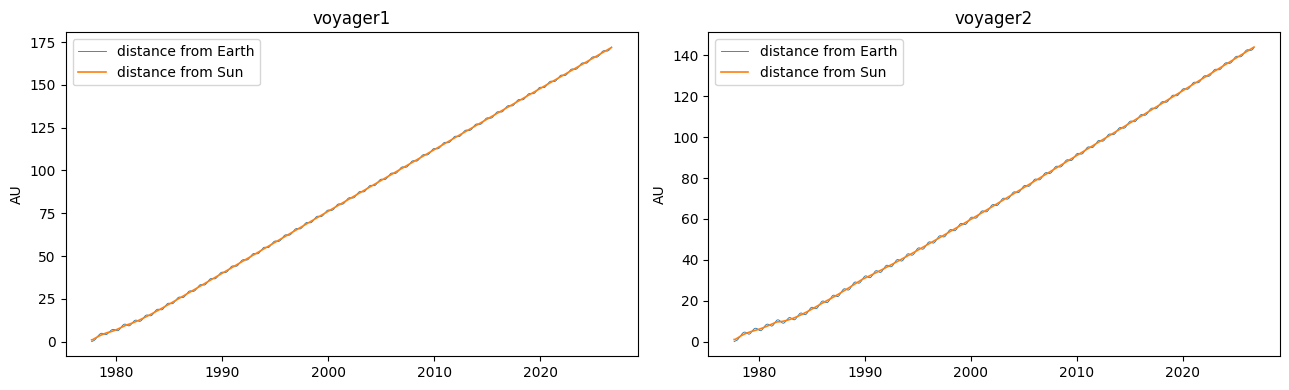

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (sc, h) in zip(axes, helio.items()):
    ax.plot(h['time'], h['r_geo_au'], lw=0.6, label='distance from Earth')
    ax.plot(h['time'], h['r_au'], lw=1.2, label='distance from Sun')
    ax.set_title(sc); ax.set_ylabel('AU'); ax.legend()
plt.tight_layout(); plt.show()

**Sanity check:** Voyager 1 should be roughly 160+ AU and Voyager 2 roughly 135+ AU from the Sun in 2025–2026.
For an independent check, compare a few dates against JPL Horizons (Section 8).

## 6. Derived features (first pass)

Resample to a uniform grid first — finite differences on an irregular grid create fake spikes.
Daily is a sensible baseline; use hourly later for zooming in on flybys.

In [ ]:
def derive_features(h, rule='1D'):
    g = h.set_index('time')[['x_au', 'y_au', 'z_au', 'r_au']].resample(rule).mean()
    g['gap'] = g['x_au'].isna()                          # keep a record of missing bins
    g = g.interpolate(limit=3)                           # only bridge tiny holes
    step_s = pd.Timedelta(rule).total_seconds()
    v = g[['x_au', 'y_au', 'z_au']].diff() * AU_KM / step_s      # km/s
    g['speed_kms']   = np.linalg.norm(v.values, axis=1)
    g['radial_kms']  = g['r_au'].diff() * AU_KM / step_s
    g['accel_kms2']  = g['speed_kms'].diff() / step_s
    # turning angle between consecutive velocity vectors (degrees)
    vv = v.values; prev = np.roll(vv, 1, axis=0)
    cos = np.einsum('ij,ij->i', vv, prev) / (np.linalg.norm(vv, axis=1) * np.linalg.norm(prev, axis=1))
    g['turn_deg'] = np.degrees(np.arccos(np.clip(cos, -1, 1)))
    g.iloc[:2, g.columns.get_loc('turn_deg')] = np.nan
    return g

feat = {sc: derive_features(h) for sc, h in helio.items()}
feat['voyager2'].describe()

,x_au,y_au,z_au,r_au,speed_kms,radial_kms,accel_kms2,turn_deg
count,17935.000000,17935.000000,17935.000000,17935.000000,17934.000000,17934.000000,1.793300e+04,17933.000000
mean,16.619270,-36.201345,-52.658692,68.208846,16.435374,13.809729,-1.630526e-08,0.084323
std,14.438012,17.902574,39.605291,42.482347,2.208189,2.319865,9.532621e-07,0.455038
min,-9.393148,-61.053093,-124.223560,1.002974,9.835019,-2.841568,-2.251672e-05,0.000107
25%,6.257063,-50.472569,-87.563378,30.854601,15.403978,13.684681,-4.568259e-08,0.030781
50%,17.789724,-39.581642,-50.440216,66.538681,15.690877,14.820236,-9.487616e-09,0.062132
75%,28.927926,-27.643601,-12.193723,105.126830,16.480461,15.025771,2.816848e-08,0.100910
max,39.885297,3.271140,1.535302,144.047943,39.041907,18.358454,8.938380e-05,37.098514


## 7. Known mission events (validation labels)

These give us **ground truth** to check whether the detector finds real events. Flybys should be the strongest signals in
trajectory data. The heliospheric boundary crossings will likely *not* show up in position data (they are plasma/magnetic-field
events), which is itself a useful result to report.

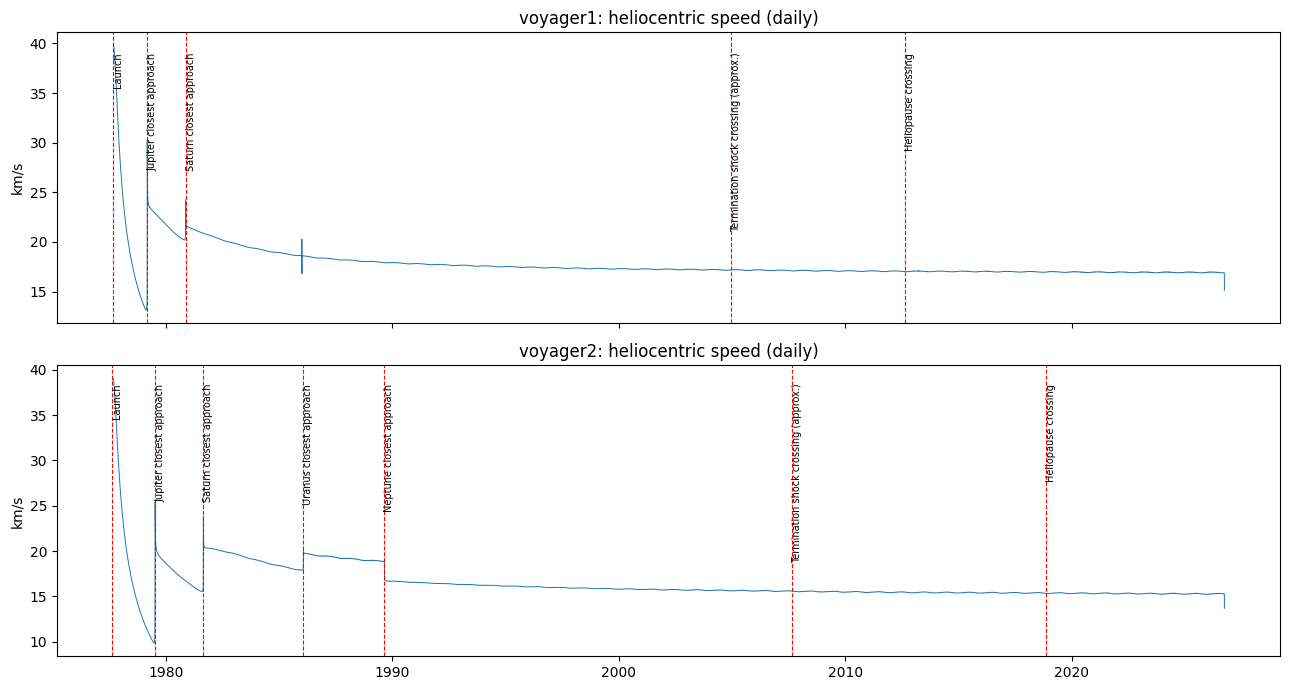

In [ ]:
events = pd.DataFrame([
    ('voyager1', '1977-09-05', 'Launch'),
    ('voyager1', '1979-03-05', 'Jupiter closest approach'),
    ('voyager1', '1980-11-12', 'Saturn closest approach'),
    ('voyager1', '2004-12-16', 'Termination shock crossing (approx.)'),
    ('voyager1', '2012-08-25', 'Heliopause crossing'),
    ('voyager2', '1977-08-20', 'Launch'),
    ('voyager2', '1979-07-09', 'Jupiter closest approach'),
    ('voyager2', '1981-08-25', 'Saturn closest approach'),
    ('voyager2', '1986-01-24', 'Uranus closest approach'),
    ('voyager2', '1989-08-25', 'Neptune closest approach'),
    ('voyager2', '2007-08-30', 'Termination shock crossing (approx.)'),
    ('voyager2', '2018-11-05', 'Heliopause crossing'),
], columns=['spacecraft', 'date', 'event'])
events['date'] = pd.to_datetime(events['date'], utc=True)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, sc in zip(axes, ['voyager1', 'voyager2']):
    ax.plot(feat[sc].index, feat[sc]['speed_kms'], lw=0.7)
    for _, e in events[events.spacecraft == sc].iterrows():
        ax.axvline(e['date'], color='red', ls='--', lw=0.8)
        ax.text(e['date'], ax.get_ylim()[1] * 0.95, e['event'], rotation=90, fontsize=7, va='top')
    ax.set_title(f'{sc}: heliocentric speed (daily)'); ax.set_ylabel('km/s')
plt.tight_layout(); plt.show()

## 8. (Optional) Cross-check against JPL Horizons

Horizons gives Sun-centered position **and velocity** directly (Voyager 1 = `-31`, Voyager 2 = `-32`).
If SSCWeb and Horizons agree, we can trust our conversion; if SSCWeb has problems, Horizons is a drop-in alternative source.

In [ ]:
from astroquery.jplhorizons import Horizons

hz = Horizons(id='-32', location='@sun',
              epochs={'start': '1989-08-01', 'stop': '1989-09-30', 'step': '1d'}).vectors()
hz_df = hz.to_pandas()[['datetime_str', 'x', 'y', 'z', 'vx', 'vy', 'vz']]   # AU and AU/day, ecliptic frame
hz_df['r_au'] = np.sqrt(hz_df.x**2 + hz_df.y**2 + hz_df.z**2)
hz_df['speed_kms'] = np.sqrt(hz_df.vx**2 + hz_df.vy**2 + hz_df.vz**2) * AU_KM / 86400
hz_df.head()
# Distances (r) are frame-independent, so compare r_au directly with helio['voyager2'] on matching dates.

,datetime_str,x,y,z,vx,vy,vz,r_au,speed_kms
0,A.D. 1989-Aug-01 00:00:00.0000,5.822094,-29.413513,0.462636,0.007368,-0.008015,0.000375,29.987757,18.861504
1,A.D. 1989-Aug-02 00:00:00.0000,5.829462,-29.421528,0.463011,0.007368,-0.008015,0.000375,29.997055,18.861508
2,A.D. 1989-Aug-03 00:00:00.0000,5.836830,-29.429543,0.463386,0.007368,-0.008015,0.000375,30.006355,18.861555
3,A.D. 1989-Aug-04 00:00:00.0000,5.844198,-29.437558,0.463761,0.007368,-0.008015,0.000375,30.015655,18.861651
4,A.D. 1989-Aug-05 00:00:00.0000,5.851566,-29.445574,0.464136,0.007368,-0.008015,0.000375,30.024957,18.861804


## 9. Summary(fill in from the outputs above)

| Item | Voyager 1 | Voyager 2 |
|---|---|---|
| Time coverage (reconstructed, up to today) | | |
| Actual sampling cadence (median / changes over time) | | |
| Variables returned | | |
| Coordinate systems available | GEO, GM, GSE, GSM, SM, GEI_TOD, GEI_J_2000 (all Earth-centered) | same |
| Format | XML/JSON via web service → `sscws` Python dict → pandas | same |
| Gaps / duplicates / missing values | | |
| Unusual features observed | | |

**Questions to decide after this step**
1. Is trajectory data alone rich enough, or do we add in-situ data (magnetic field / plasma from CDAWeb) so "anomalies" include boundary crossings?
2. Which resolution for modeling: daily for the full mission, hourly around flybys?
3. Which features and which detectors (e.g., rolling z-score baseline, Isolation Forest, LOF, autoencoder)?